In [1]:
import numpy as np

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results

from particle_filter.performance_metrics import RMSE, ESS, Interval_cover

In [2]:
# Funcion de transición
omega = 10.0
rho = 28.0
beta = 8/3

def lorenz_system(coordinates):

    x, y, z = coordinates

    return np.array([
        omega * (y - x),
        x * (rho - z) - y,
        x * y - beta * z
    ])


dt = 0.01

def lorenz_system_RK(coordinates):

    k1 = lorenz_system(coordinates)

    k2 = lorenz_system(coordinates + k1 * (dt / 2))

    k3 = lorenz_system(coordinates + k2 * (dt / 2))

    k4 = lorenz_system(coordinates + dt * k3)

    return coordinates + (dt/6) * (k1 + 2 * k2 + 2 * k3 + k4)

In [3]:
# Funcion de observación
def obs(coordinates):

    x,y,z = coordinates

    return np.array([x,y,z])

In [12]:
# Ecuacion de transicion
#diag_values = [0.0, 0.0, 0.0, 1.0, 1.0, 1.0]
Q = np.eye(3)
noise_transition = GaussianNoise(Q)
transition_equation = AdditiveTransitionModel(lorenz_system_RK, noise_transition)

# Ecuacion de observacion
R = np.eye(3)
noise_observation = GaussianNoise(R)
observation_equation = AdditiveObservationModel(obs, noise_observation)

In [ ]:
# Simulacion
T = 10000
x0 = np.array([0.9, 0.0, 0.0])

x_true, y_obs = system_simulation(transition_equation, observation_equation, x0, T)

In [6]:
import pickle

with open("y_obs_1.pkl", "rb") as file:
    y_obs = pickle.load(file)

with open("x_true_1.pkl", "rb") as file:
    x_true = pickle.load(file)

with open("results_bpf_1.pkl", "rb") as file:
    est_bpf = pickle.load(file)    

In [13]:
# Filtrado Bootstrap
bpf = BootstrapParticleFilter(1000, transition_equation, observation_equation)
bpf.initialize(mean=np.array([0.0, 0.0, 0.0]), cov=np.diag([1.0, 1.0, 1.0]))
est_bpf = bpf.run_filter(y_obs, bpf.N/2)
print("Bootstrap finalizado")

Bootstrap finalizado


In [133]:
# Filtrado Auxiliary
apf = AuxiliaryParticleFilter(1000, transition_equation, observation_equation)
apf.initialize(mean=np.array([10.0, 28.0, 8/3, 0.0, 0.0, 0.0]), cov=np.diag([0.5, 1.0, 0.1, 1.0, 1.0, 1.0]))
est_apf = apf.run_filter(y_obs, apf.N/2)
print("Auxiliary finalizado")

Auxiliary finalizado


In [16]:
print("Bootstrap")

print(f"RMSE x: {RMSE(x_true[:, 0], est_bpf["estimates"][:, 0])}")
print(f"RMSE y: {RMSE(x_true[:, 1], est_bpf["estimates"][:, 1])}")
print(f"RMSE z: {RMSE(x_true[:, 2], est_bpf["estimates"][:, 2])}")

print(f"Log-likelihood: {est_bpf["log_likelihood"]}")

print(f"IC: {Interval_cover(x_true, est_bpf["intervals"])}")

Bootstrap
RMSE x: 0.96463134054573
RMSE y: 1.1068403491389556
RMSE z: 1.1649245043168401
Log-likelihood: -56306.326920875406
IC: 64.59


In [17]:
import pickle

with open("x_true_1.pkl", "wb") as file:
    pickle.dump(x_true, file)

with open("y_obs_1.pkl", "wb") as file:
    pickle.dump(y_obs, file)

with open("results_bpf_1.pkl", "wb") as file:
    pickle.dump(est_bpf, file)

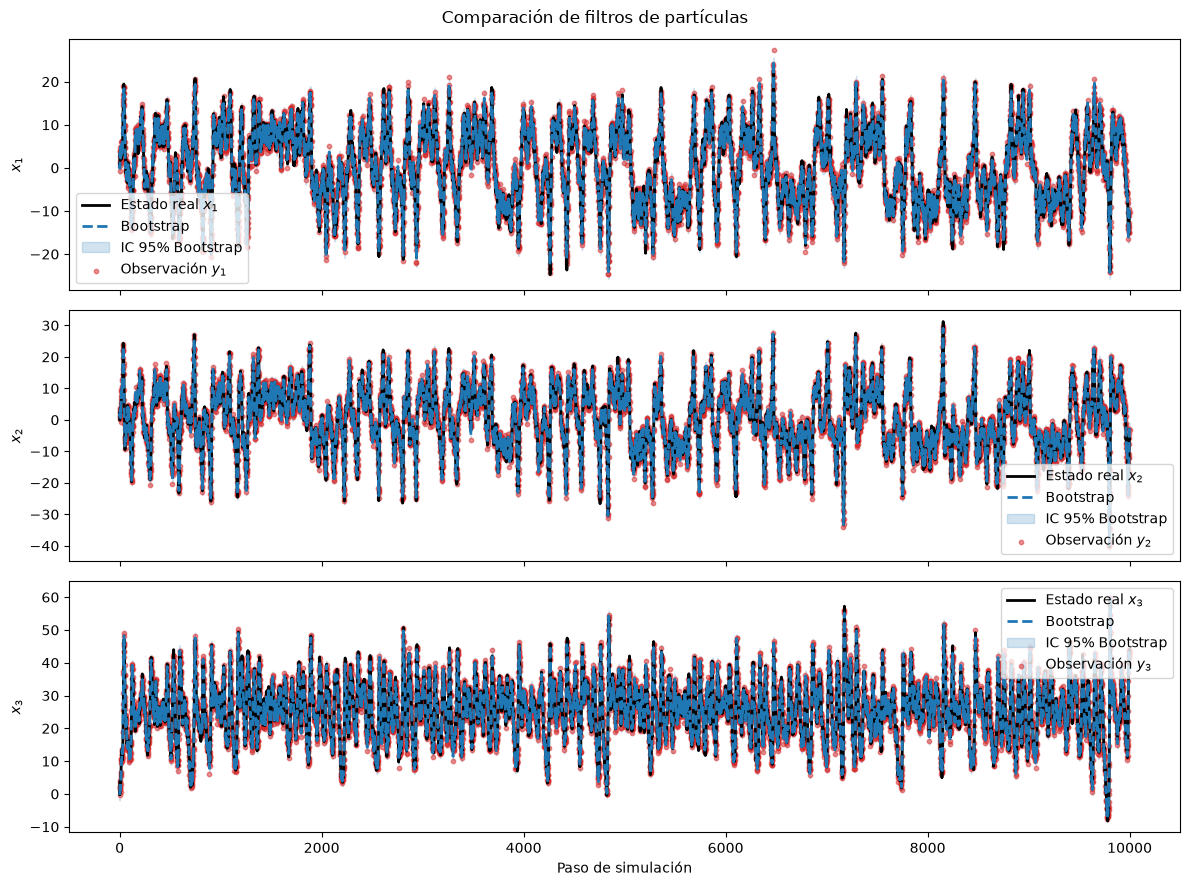

In [26]:
i=0
f=10000
plot_results(x_true[i:f,:], y_obs[i:f,:], {"Bootstrap": est_bpf["estimates"][i:f,:]}, confidence_intervals={"Bootstrap": est_bpf["intervals"][i:f,:]})

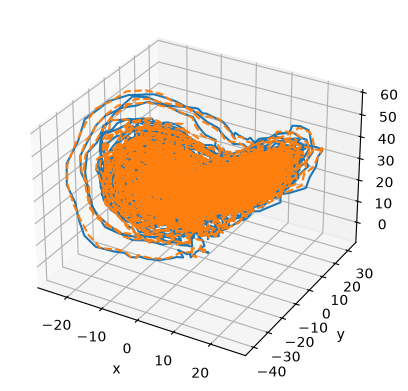

In [28]:
import matplotlib.pyplot as plt

fig = plt.figure()

ax = fig.add_subplot(111, projection="3d")

ax.plot(
    x_true[:,0],
    x_true[:,1],
    x_true[:,2],
    label="Real"
)

ax.plot(
    est_bpf["estimates"][:,0],
    est_bpf["estimates"][:,1],
    est_bpf["estimates"][:,2],
    label="Predicho",
    linestyle="--"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

plt.show()

### Escenario 2: Estimación de parámetros

In [2]:
import pickle

with open("y_obs_1.pkl", "rb") as file:
    y_obs = pickle.load(file)

with open("x_true_1.pkl", "rb") as file:
    x_true = pickle.load(file)

In [41]:
# Funcion de transición

def parameters_from_thehta(theta):

    theta_omega, theta_rho, theta_beta = theta

    return (
        np.exp(theta_omega),
        np.exp(theta_rho),
        np.exp(theta_beta)
    )


def lorenz_system(coordinates):

    theta_omega, theta_rho, theta_beta, x, y, z = coordinates

    omega, rho, beta = parameters_from_thehta(
        [theta_omega, theta_rho, theta_beta]
    )

    return np.array([
        0.0,
        0.0,
        0.0,
        omega * (y - x),
        x * (rho - z) - y,
        x * y - beta * z
    ])


dt = 0.01

def lorenz_system_RK(coordinates):

    k1 = lorenz_system(coordinates)

    k2 = lorenz_system(coordinates + k1 * (dt / 2))

    k3 = lorenz_system(coordinates + k2 * (dt / 2))

    k4 = lorenz_system(coordinates + dt * k3)

    return coordinates + (dt/6) * (k1 + 2 * k2 + 2 * k3 + k4)

In [42]:
# Funcion de observación
def obs(coordinates):

    _,_,_,x,y,z = coordinates

    return np.array([x,y,z])

In [43]:
# Ecuacion de transicion
diag_values = [1e-8, 1e-8, 1e-8, 1.0, 1.0, 1.0]
Q = np.diag(diag_values)
noise_transition = GaussianNoise(Q)
transition_equation = AdditiveTransitionModel(lorenz_system_RK, noise_transition)

# Ecuacion de observacion
R = np.eye(3)
noise_observation = GaussianNoise(R)
observation_equation = AdditiveObservationModel(obs, noise_observation)

In [36]:
# Filtrado Bootstrap
bpf = BootstrapParticleFilter(1000, transition_equation, observation_equation)
bpf.initialize(mean=np.array([np.log(10), np.log(28), np.log(8/3), 0.0, 0.0, 0.0]), cov=np.diag([1e-5, 1e-5, 1e-5, 1.0, 1.0, 1.0]))
est_bpf = bpf.run_filter(y_obs, bpf.N/2)
print("Bootstrap finalizado")

with open("results_bpf_3.pkl", "wb") as file:
    pickle.dump(est_bpf, file)


Bootstrap finalizado


In [3]:
with open("results_bpf_3.pkl", "rb") as file:
    est_bpf = pickle.load(file)

In [4]:
print("Bootstrap")

print(f"RMSE x: {RMSE(x_true[:, 0], est_bpf["estimates"][:, 3])}")
print(f"RMSE y: {RMSE(x_true[:, 1], est_bpf["estimates"][:, 4])}")
print(f"RMSE z: {RMSE(x_true[:, 2], est_bpf["estimates"][:, 5])}")

print(f"Log-likelihood: {est_bpf["log_likelihood"]}")

print(f"IC parametros: {Interval_cover(x_true[:,0:3], est_bpf["intervals"][:,3:])}")

Bootstrap
RMSE x: 0.9650903428530239
RMSE y: 1.1018636562763267
RMSE z: 1.1667477651888372
Log-likelihood: -56306.93519725121
IC parametros: 64.4


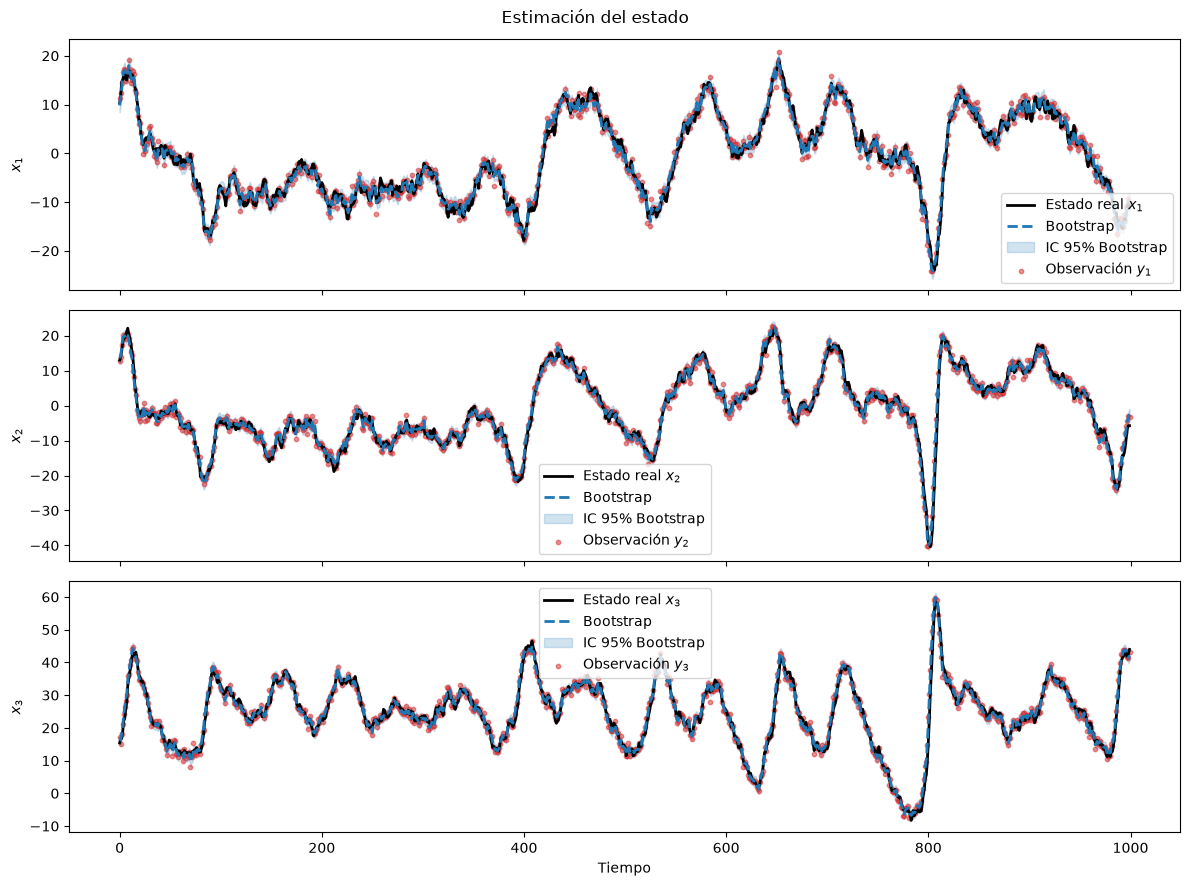

In [85]:
i=9000
f=10000
plot_results(x_true[i:f,:], y_obs[i:f,:], {"Bootstrap": est_bpf["estimates"][i:f,3:]}, confidence_intervals={"Bootstrap": est_bpf["intervals"][i:f,3:]}, x_title="Tiempo", plot_title="Estimación del estado")

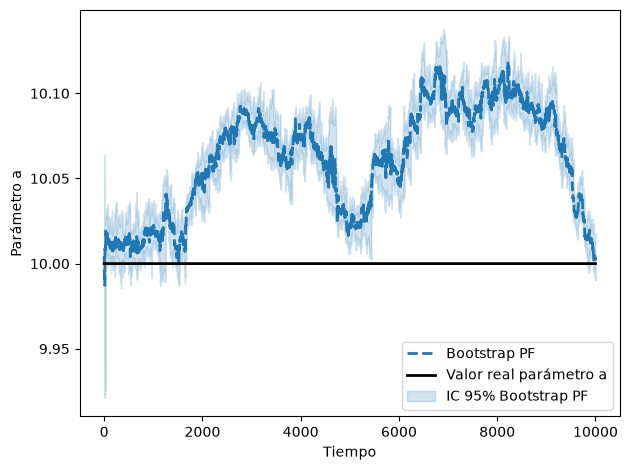

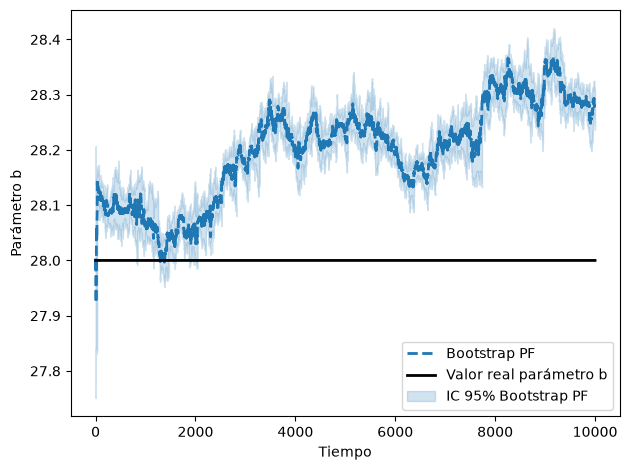

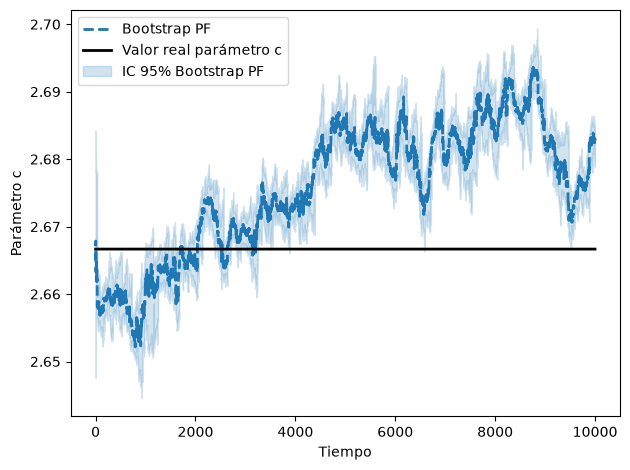

In [6]:
import matplotlib.pyplot as plt

T=10000

for parameter, value, state in zip(["a","b","c"],[10,28,8/3], [0,1,2]):

    res = np.exp(est_bpf["estimates"][:,state])
    intervals = np.exp(est_bpf["intervals"][:,state,:])

    plt.plot(figsize=(12, 1))

    plt.plot(np.arange(T), res, color="tab:blue", linewidth=2, linestyle="--", label="Bootstrap PF")
    plt.plot(np.arange(T), np.full(T, value), color="black", linewidth=2, label=f"Valor real parámetro {parameter}")
    plt.fill_between(np.arange(T), intervals[:,0], intervals[:,1], color="tab:blue", alpha=0.2, label=f"IC 95% {"Bootstrap PF"}")

    plt.xlabel("Tiempo")
    plt.ylabel(f"Parámetro {parameter}")
    #plt.title(f"Valor estimado del parámetro {parameter}")

    plt.legend()

    plt.tight_layout()
    plt.show()


In [45]:
# Filtrado Auxiliary
apf = AuxiliaryParticleFilter(1000, transition_equation, observation_equation)
apf.initialize(mean=np.array([np.log(10), np.log(28), np.log(8/3), 0.0, 0.0, 0.0]), cov=np.diag([1e-5, 1e-5, 1e-5, 1.0, 1.0, 1.0]))
est_apf = apf.run_filter(y_obs, apf.N/2)
print("Auxiliary finalizado")

with open("results_apf_1.pkl", "wb") as file:
    pickle.dump(est_apf, file)


Auxiliary finalizado


In [7]:
with open("results_apf_1.pkl", "rb") as file:
    est_apf = pickle.load(file)

In [81]:
print("Auxiliary")

print(f"RMSE x: {RMSE(x_true[:, 0], est_apf["estimates"][:, 3])}")
print(f"RMSE y: {RMSE(x_true[:, 1], est_apf["estimates"][:, 4])}")
print(f"RMSE z: {RMSE(x_true[:, 2], est_apf["estimates"][:, 5])}")

print(f"Log-likelihood: {est_apf["log_likelihood"]}")

print(f"IC: {Interval_cover(x_true[:,0:3], est_apf["intervals"][:,3:])}")

Auxiliary
RMSE x: 0.9691021078264866
RMSE y: 1.1105623303486991
RMSE z: 1.1652981451055109
Log-likelihood: -56399.29558293341
IC: 64.42999999999999


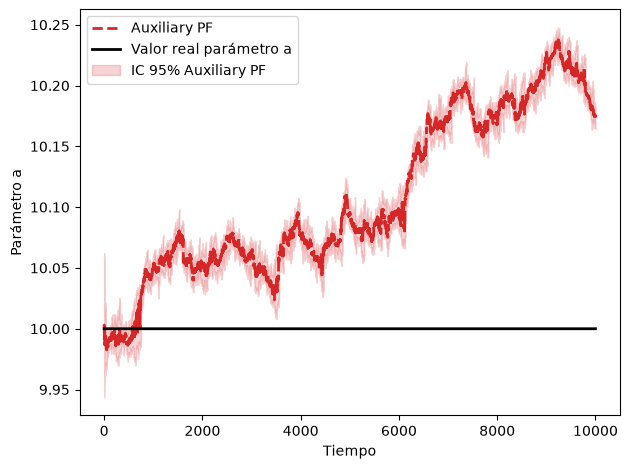

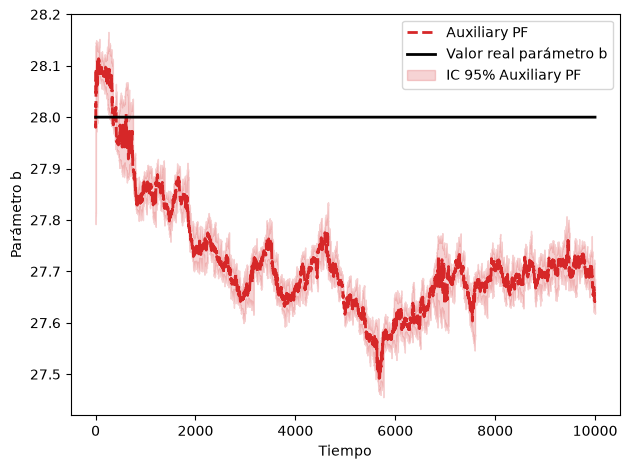

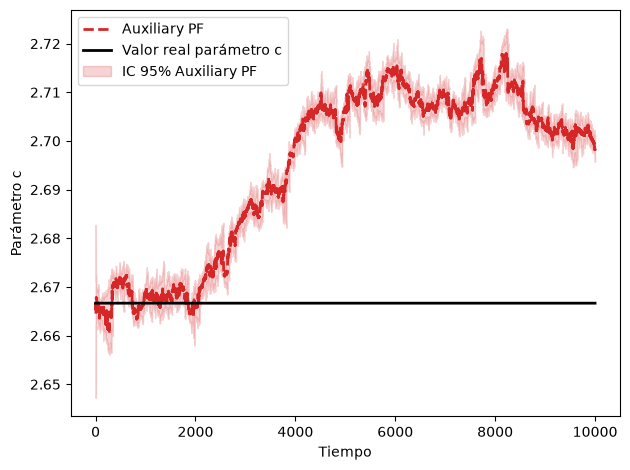

In [8]:
import matplotlib.pyplot as plt

T=10000

for parameter, value, state in zip(["a","b","c"],[10,28,8/3], [0,1,2]):

    res = np.exp(est_apf["estimates"][:,state])
    intervals = np.exp(est_apf["intervals"][:,state,:])

    plt.plot(figsize=(12, 1))

    plt.plot(np.arange(T), res, color="tab:red", linewidth=2, linestyle="--", label="Auxiliary PF")
    plt.plot(np.arange(T), np.full(T, value), color="black", linewidth=2, label=f"Valor real parámetro {parameter}")
    plt.fill_between(np.arange(T), intervals[:,0], intervals[:,1], color="tab:red", alpha=0.2, label=f"IC 95% {"Auxiliary PF"}")

    plt.xlabel("Tiempo")
    plt.ylabel(f"Parámetro {parameter}")
    #plt.title(f"Valor estimado del parámetro {parameter}")

    plt.legend()

    plt.tight_layout()
    plt.show()

In [92]:
print(f"Parameters: {np.exp(est_apf["estimates"][-1,0])}")
print(f"Parameters: {np.exp(est_apf["estimates"][-1,1])}")
print(f"Parameters: {np.exp(est_apf["estimates"][-1,2])}")

Parameters: 10.175141441161022
Parameters: 27.644290405182993
Parameters: 2.6980084871421477


### Comparación de trayectorias con parámetros veraderos y estimados

In [27]:
# Funcion de transición
omega = 10.0159869
rho = 27.95983371
beta = 2.65489772

def lorenz_system(coordinates):

    x, y, z = coordinates

    return np.array([
        omega * (y - x),
        x * (rho - z) - y,
        x * y - beta * z
    ])


dt = 0.01

def lorenz_system_RK(coordinates):

    k1 = lorenz_system(coordinates)

    k2 = lorenz_system(coordinates + k1 * (dt / 2))

    k3 = lorenz_system(coordinates + k2 * (dt / 2))

    k4 = lorenz_system(coordinates + dt * k3)

    return coordinates + (dt/6) * (k1 + 2 * k2 + 2 * k3 + k4)

In [28]:
# Funcion de observación
def obs(coordinates):

    x,y,z = coordinates

    return np.array([x,y,z])

In [29]:
# Ecuacion de transicion
Q = np.zeros((3,3))
noise_transition = GaussianNoise(Q)
transition_equation = AdditiveTransitionModel(lorenz_system_RK, noise_transition)

# Ecuacion de observacion
R = np.zeros((3,3))
noise_observation = GaussianNoise(R)
observation_equation = AdditiveObservationModel(obs, noise_observation)

In [30]:
T=10000
x0 = np.array([0.9, 0.0, 0.0])

x_approx, _ = system_simulation(transition_equation, observation_equation, x0, T)

In [38]:
print(f"RMSE coord x: {RMSE(x_accurate[:,0], x_approx[:,0])}")
print(f"RMSE coord y: {RMSE(x_accurate[:,1], x_approx[:,1])}")
print(f"RMSE coord z: {RMSE(x_accurate[:,2], x_approx[:,2])}")

RMSE coord x: 9.346718222755953
RMSE coord y: 10.76470824523544
RMSE coord z: 10.317352075296737


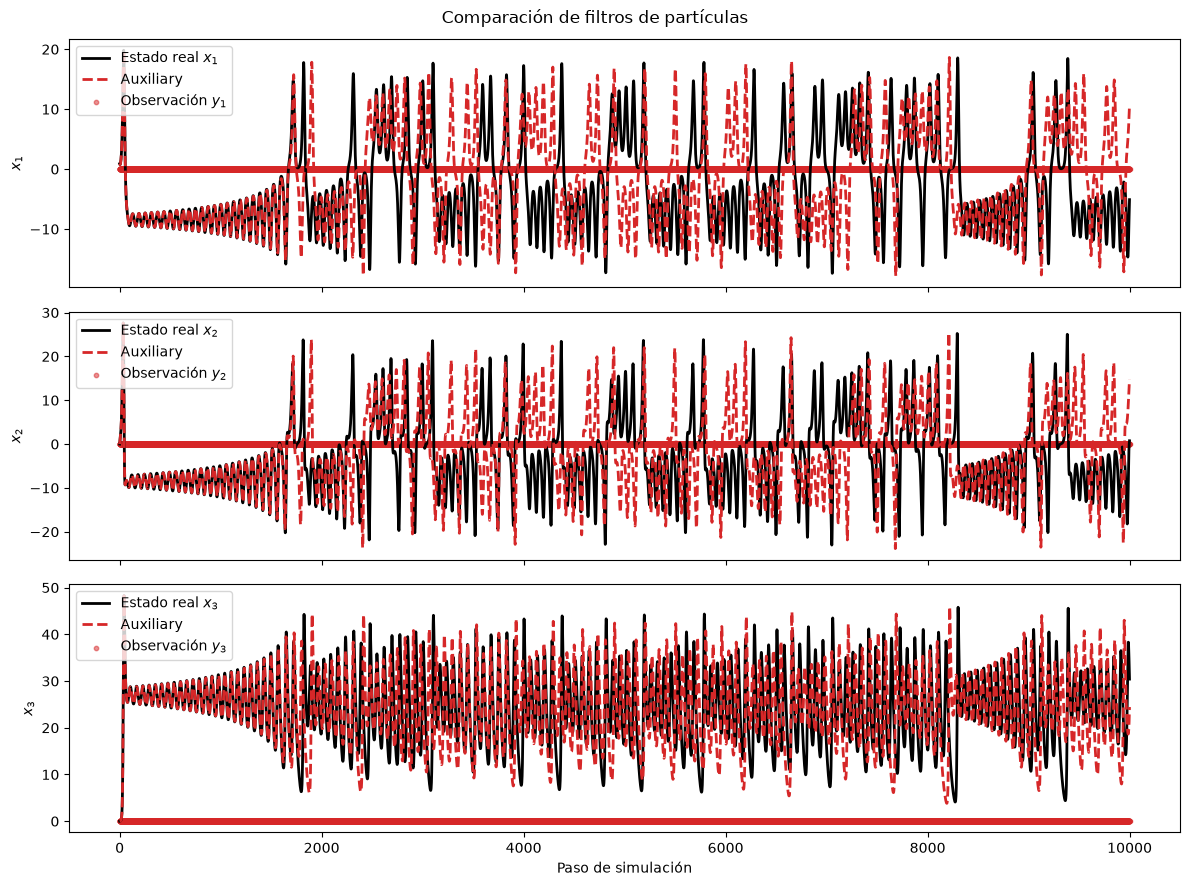

In [40]:
plot_results(x_accurate, np.full((10000, 3), 0), {"Auxiliary": x_approx})